# Graphite Benchmarks – Big Experiments

## Libraries

In [1]:
from fabric import ThreadingGroup, Connection
from chi import server, ssh
import os
import warnings
import time
import sys
sys.path.append('../scripts')
from utilities import *
warnings.filterwarnings('ignore')

## Configurations

In [2]:
sshUser = "ubuntu"
server_ips = ["64.131.114.155"]
server_local_ips = {}
client_ips = ["64.131.114.143", "64.131.114.145", "64.131.114.146", "64.131.114.147",
              "64.131.114.148", "64.131.114.152", "64.131.114.153", "64.131.114.154"]

storageType = {"HDD": "/HDD", "NVME": "/NVME_RAID-0"}
SERVER_WORKING_DIR = storageType["NVME"]

## Initialize environment

In [3]:
# These groups are for processing in parallel 
serverConnections = [makeConnection(i, user=sshUser) for i in server_ips]
clientConnections = [makeConnection(i, user=sshUser) for i in client_ips]
allConnections = (serverConnections + clientConnections)
serverGroup = ThreadingGroup.from_connections(serverConnections)
clientGroup = ThreadingGroup.from_connections(clientConnections)
allGroup = ThreadingGroup.from_connections(allConnections)

# Get local IP for server
local_ips = serverGroup.run("hostname -I | cut -d ' ' -f 1", hide=True)
for i in local_ips:
    server_local_ips[i.host] = local_ips[i].stdout.strip()

# Update & Upgrade latest packages
allGroup.run("sudo apt update && sudo apt upgrade -y", hide=True)
rebootGroup(allGroup)

Wait for all server to come online after reboot

In [4]:
# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

## Datasets

Preparing test datasets on client nodes

In [5]:
clientGroup.put("../scripts/initData.sh")
clientGroup.run("bash initData.sh MYSTIC@IIT", hide=True);

## Benchmark server (Graphite – Go-Carbon)

Prepare benchmark server

In [6]:
serverGroup.put("../scripts/Graphite/initGraphiteServer.sh")
serverGroup.put("../scripts/Graphite/go-carbon.conf")
serverGroup.put("../scripts/Graphite/carbon-api.yaml")
serverGroup.put("../scripts/Graphite/graphiteWeb.yaml")
serverGroup.put("../scripts/Graphite/storage-schemas.conf")
serverGroup.run(f"sudo chmod -R 777 {SERVER_WORKING_DIR}; bash initGraphiteServer.sh {SERVER_WORKING_DIR}", hide=True);

## Benchmark client (XBench)
Prepare benchmark client

In [7]:
clientGroup.put("../scripts/initXBenchClient.sh")
clientGroup.run("bash initXBenchClient.sh", hide=True)
clientGroup.close()

## Experiments - Settings

In [8]:
targetThreads = [1, 2, 4, 8]
numClients = [i * len(client_ips) for i in targetThreads]

## Experiment – UNARY INSERT (SEQ)
**Perform experiments**

In [9]:
runWorkload("INSERT_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 2003, "Graphite", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774458816
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774458764 | Delta: 52
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774458995
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774458941 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774459181
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774459127 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774459437
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774459323 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774459330 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

**Visualization**

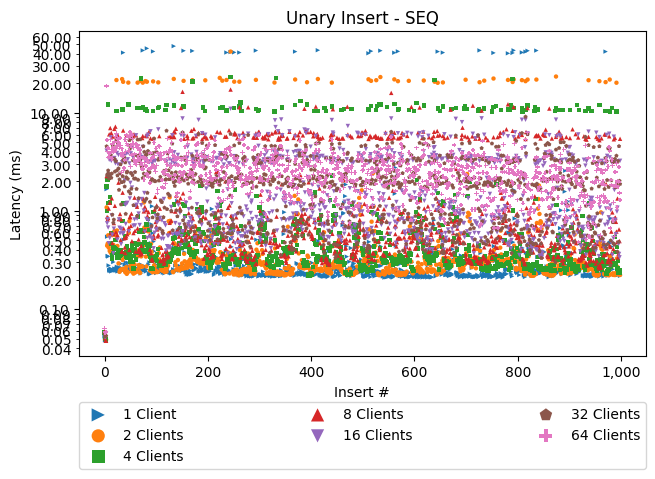

In [10]:
unaryPlots("INSERT_UNARY_SEQ", "Graphite", targetThreads, client_ips, "Insert", logScale=True)

## Experiment – UNARY INSERT (RAND)
**Perform experiments**

In [11]:
runWorkload("INSERT_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 2003, "Graphite", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774460836
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774460782 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774461016
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774460962 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774461201
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774461147 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774461459
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774461345 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774461351 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

**Visualization**

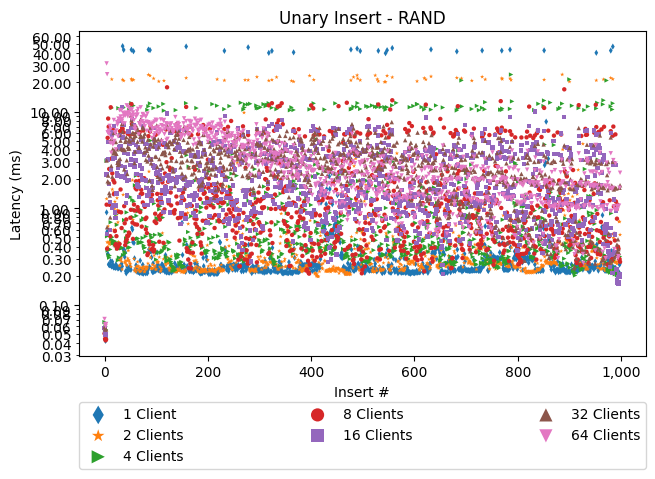

In [12]:
unaryPlots("INSERT_UNARY_RAND", "Graphite", targetThreads, client_ips, "Insert", logScale=True)

## Experiment – BATCH INSERT (SEQ)
**Perform experiments**

In [13]:
runWorkload("INSERT_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 2003, "Graphite", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774462907
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774462854 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774463086
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774463033 | Delta: 53
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774463271
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774463218 | Delta: 53
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774463527
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774463414 | Delta: 113
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774463421 | Delta: 106
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

**Visualization**

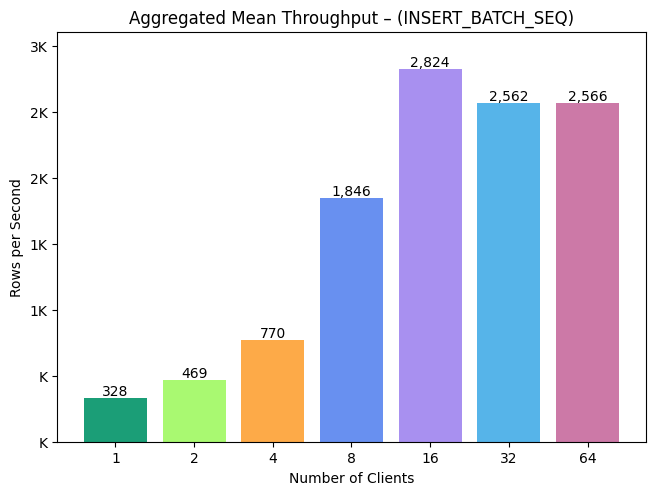

In [14]:
batchPlots("INSERT_BATCH_SEQ", "Graphite", targetThreads, client_ips)

## Experiment – BATCH INSERT (RAND)
**Perform experiments**

In [15]:
runWorkload("INSERT_BATCH_RAND", targetThreads, server_local_ips[server_ips[0]], 2003, "Graphite", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774465240
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774465187 | Delta: 53
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774465425
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774465371 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774465620
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774465567 | Delta: 53
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774465892
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774465779 | Delta: 113
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774465786 | Delta: 106
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

**Visualization**

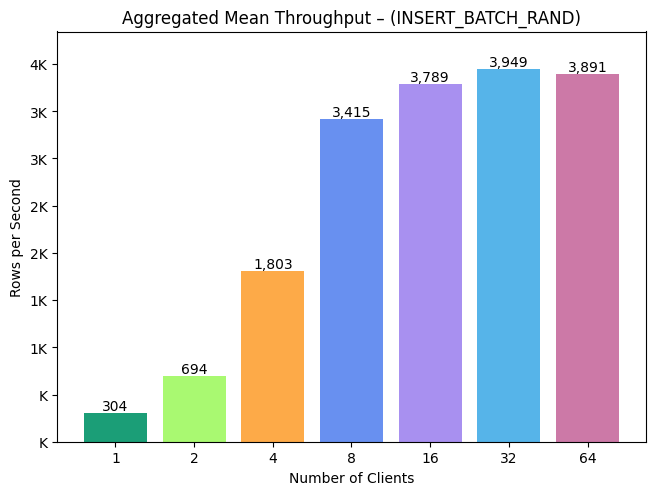

In [16]:
batchPlots("INSERT_BATCH_RAND", "Graphite", targetThreads, client_ips)

## Bootstrap Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [17]:
rebootGroup(allGroup)

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

<div class="alert alert-block alert-info">Note: This is required so that there's actual data for clients to query from</div>

In [18]:
serverGroup.put("../scripts/restoreDB.sh")

# Restore DB
serverGroup.run(f"bash restoreDB.sh MYSTIC@IIT Graphite BENCH_DB {SERVER_WORKING_DIR}", hide=True)

# Keep checking if job is done running in tmux window
checkTmuxJobIsDone(serverGroup);

## Experiment – UNARY QUERY (SEQ)

**Perform experiments**

In [19]:
runWorkload("QUERY_UNARY_SEQ", targetThreads, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774488301
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774488247 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774488475
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774488421 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774488655
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774488600 | Delta: 55
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774488906
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774488792 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774488799 | Delta: 107
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

**Visualization**

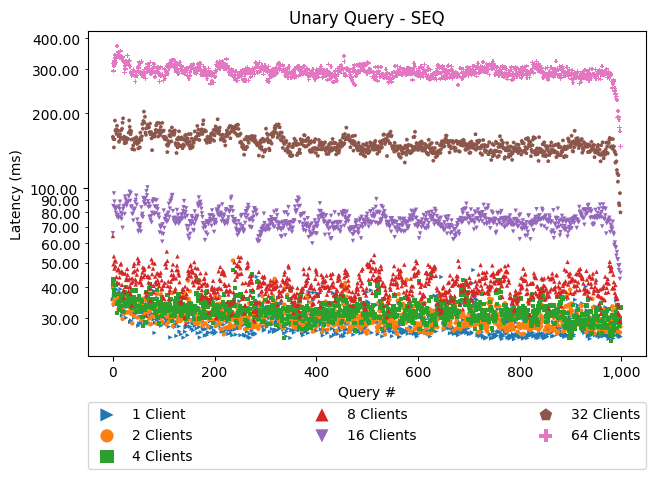

In [20]:
unaryPlots("QUERY_UNARY_SEQ", "Graphite", targetThreads, client_ips, "Query", logScale=True)

## Experiment – UNARY QUERY (RAND)

**Perform experiments**

In [21]:
runWorkload("QUERY_UNARY_RAND", targetThreads, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774490678
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774490624 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774490853
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774490799 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774491034
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774490979 | Delta: 55
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774491287
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774491173 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774491179 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

**Visualization**

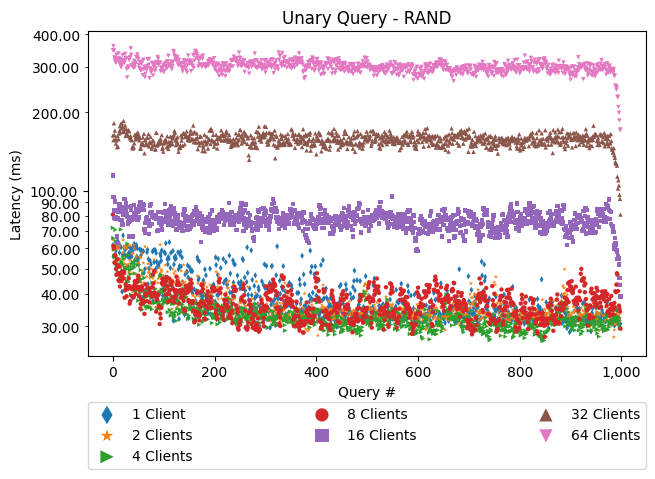

In [22]:
unaryPlots("QUERY_UNARY_RAND", "Graphite", targetThreads, client_ips, "Query", logScale=True)

## Experiment – BATCH QUERY (SEQ)

**Perform experiments**

In [23]:
runWorkload("QUERY_BATCH_SEQ", targetThreads, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774493095
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774493041 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774493269
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774493215 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774493449
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774493395 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774493700
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774493586 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774493592 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

**Visualization**

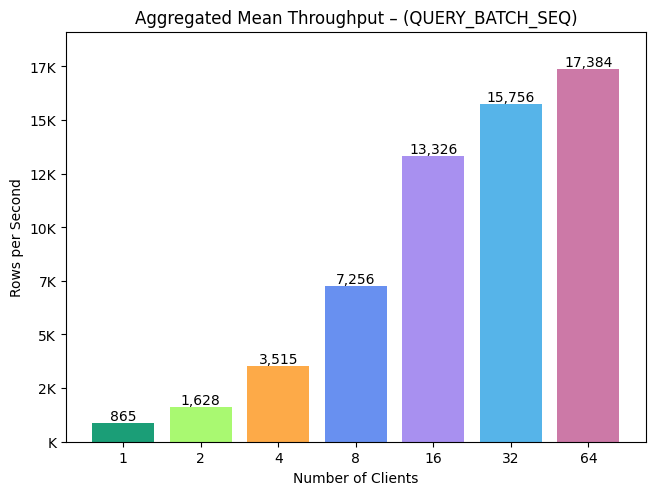

In [24]:
batchPlots("QUERY_BATCH_SEQ", "Graphite", targetThreads, client_ips, 100)

## Refresh Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [25]:
rebootGroup(allGroup)

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

## Experiment – MIN AGG QUERY

**Perform experiments**

In [26]:
runWorkload("AGG_MIN_QUERY", targetThreads, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774495381
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774495327 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774495556
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774495501 | Delta: 55
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774495735
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774495681 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774495986
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774495872 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774495878 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

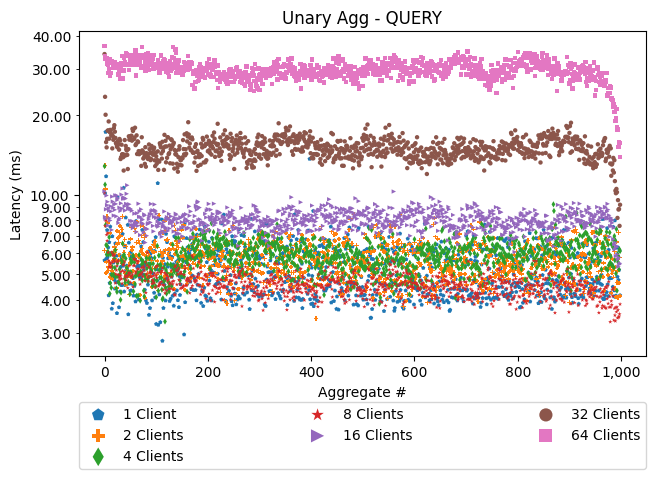

In [27]:
unaryPlots("AGG_MIN_QUERY", "Graphite", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – MAX AGG QUERY

**Perform experiments**

In [28]:
runWorkload("AGG_MAX_QUERY", targetThreads, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774497371
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774497317 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774497546
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774497491 | Delta: 55
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774497726
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774497672 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774497977
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774497863 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774497869 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

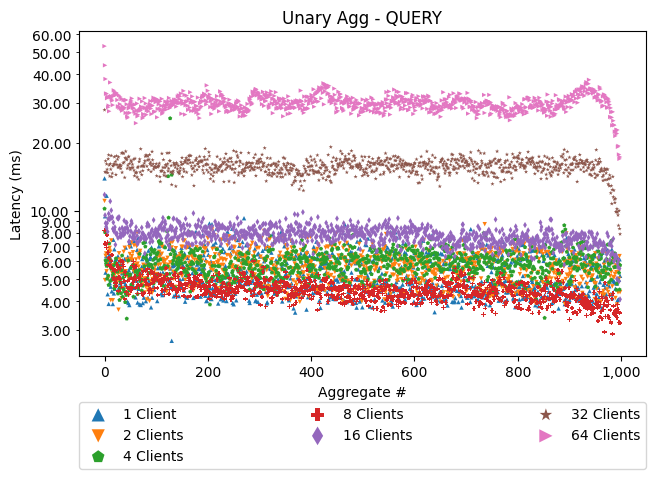

In [29]:
unaryPlots("AGG_MAX_QUERY", "Graphite", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – SUM AGG QUERY

**Perform experiments**

In [30]:
runWorkload("AGG_SUM_QUERY", targetThreads, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774499360
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774499306 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774499534
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774499480 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774499714
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774499659 | Delta: 55
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774499965
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774499851 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774499857 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

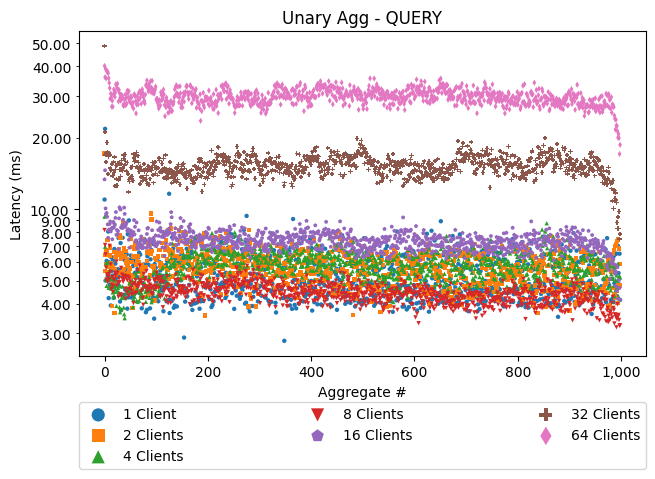

In [31]:
unaryPlots("AGG_SUM_QUERY", "Graphite", targetThreads, client_ips, "Aggregate", logScale=True)

## Experiment – AVG AGG QUERY

**Perform experiments**

In [32]:
runWorkload("AGG_AVG_QUERY", targetThreads, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark: 1] - Schedule workload on 1774501348
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1774501294 | Delta: 54
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark: 2] - Schedule workload on 1774501522
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1774501468 | Delta: 54
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark: 4] - Schedule workload on 1774501701
[Benchmark: 4] [Client: 64.131.114.143] - Time now: 1774501647 | Delta: 54
[Benchmark: 4] [Client: 64.131.114.143] - Downloaded 4 result files
[Benchmark: 4] [Server] - Downloaded system stats files
[Benchmark: 8] - Schedule workload on 1774501952
[Benchmark: 8] [Client: 64.131.114.143] - Time now: 1774501838 | Delta: 114
[Benchmark: 8] [Client: 64.131.114.145] - Time now: 1774501844 | Delta: 108
[Benchmark: 8] [Client: 64.131.114.146] - Time now: 177

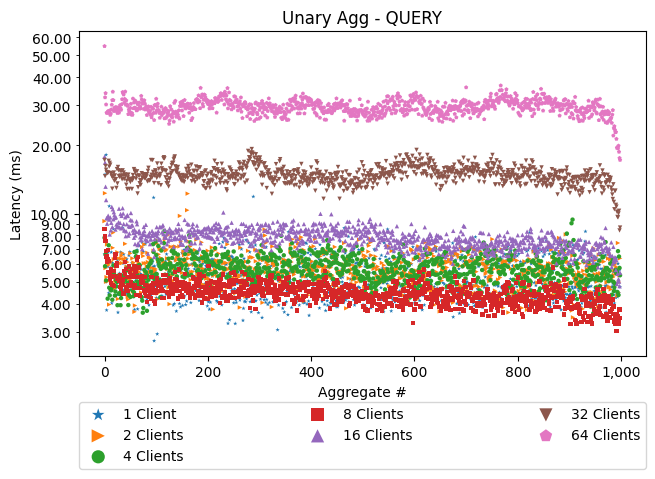

In [33]:
unaryPlots("AGG_AVG_QUERY", "Graphite", targetThreads, client_ips, "Aggregate", logScale=True)